In [2]:
import pandas as pd
import os

os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")

# Load the dataset
df = pd.read_csv('global_power_plant_database.csv')

# Filter for Spain and renewable energy sources
df_spain = df[(df['country'] == 'ESP') & (df['primary_fuel'].isin(['Wind', 'Solar']))]

# Display the filtered data
print(df_spain[['name', 'primary_fuel', 'capacity_mw', 'latitude', 'longitude']])


                       name primary_fuel  capacity_mw  latitude  longitude
20138                AGREDA         Wind        18.00   41.8559    -1.9224
20145            ALENTISQUE         Wind        46.50   41.4206    -2.3319
20146     ALTO DE LA SIERRA         Wind        11.05   41.5406    -1.7166
20148  AMPLIACION DEL PICAL         Wind        11.05   42.9362    -4.3083
20149  AMPLIACION PADORNELO         Wind        18.00   42.0357    -6.9054
...                     ...          ...          ...       ...        ...
20959               Zaratán        Solar         9.00   41.6428    -4.8151
20960                 Zarza        Solar         7.60   39.8710    -6.8320
20961               Zuera I        Solar         9.00   41.9340    -0.8050
20962              Zuera II        Solar         9.90   41.9440    -0.8180
20963                 Zújar        Solar         7.00   38.9420    -5.8750

[585 rows x 5 columns]


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11152\3841401000.py:7: DtypeWarning: Columns (10,17,18,26,27,37,38) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('global_power_plant_database.csv')


In [3]:
# Filter for Spain and renewable energy sources
df_wind_spain = df[(df['country'] == 'ESP') & (df['primary_fuel'].isin(['Wind'])) & (df['longitude'] < 10)]
df_wind_spain

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017,Unnamed: 36,Unnamed: 37,Unnamed: 38
20138,ESP,Spain,AGREDA,WRI1006162,18.00,41.8559,-1.9224,Wind,NaN,NaN,...,51.20,50.55,NO-ESTIMATION,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20145,ESP,Spain,ALENTISQUE,WRI1006179,46.50,41.4206,-2.3319,Wind,NaN,NaN,...,119.89,117.78,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20146,ESP,Spain,ALTO DE LA SIERRA,WRI1006185,11.05,41.5406,-1.7166,Wind,NaN,NaN,...,NaN,23.50,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1,NaN,NaN,NaN
20148,ESP,Spain,AMPLIACION DEL PICAL,WRI1006191,11.05,42.9362,-4.3083,Wind,NaN,NaN,...,NaN,23.50,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1,NaN,NaN,NaN
20149,ESP,Spain,AMPLIACION PADORNELO,WRI1006192,18.00,42.0357,-6.9054,Wind,NaN,NaN,...,43.73,43.80,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20874,ESP,Spain,SERRA DE RUBIO,WRI1007897,75.00,41.6485,1.5914,Wind,NaN,NaN,...,211.82,194.42,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20875,ESP,Spain,SERRA DE VILOBI,WRI1007900,40.50,42.1555,2.2828,Wind,NaN,NaN,...,108.59,102.13,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20876,ESP,Spain,SERRA DEL TALLAT,WRI1007901,49.50,42.3833,2.2667,Wind,NaN,NaN,...,131.29,119.51,WIND-V1,WIND-V1,WIND-V1,WIND-V1,WIND-V1,NaN,NaN,NaN
20877,ESP,Spain,SIERRA DE LA VIRGEN,WRI1007912,24.42,41.5406,-1.7166,Wind,NaN,NaN,...,NaN,51.93,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1,NaN,NaN,NaN


In [4]:
from sklearn.cluster import KMeans
import numpy as np
# Préparer les coordonnées (latitude, longitude)
coords = df_wind_spain[['latitude', 'longitude']].values

# Appliquer KMeans avec 50 clusters
kmeans = KMeans(n_clusters=50, random_state=0)
df_wind_spain['group'] = kmeans.fit_predict(coords)

# Vérifier que ça fait bien 50 groupes (300/6 = 50)
print("Nombre de groupes:", df_wind_spain['group'].nunique())

# Fonction pour calculer barycentre pondéré par capacity_mw
def weighted_centroid(group):
    weights = group['capacity_mw']
    lat = np.average(group['latitude'], weights=weights)
    lon = np.average(group['longitude'], weights=weights)
    total_capacity = weights.sum()
    return pd.Series({'latitude': lat, 'longitude': lon, 'total_capacity_mw': total_capacity})

# Appliquer la fonction par groupe
df_grouped = df_wind_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)

print(df_grouped.head())

Nombre de groupes: 50
    latitude  longitude  total_capacity_mw
0  42.282151  -7.606360             293.06
1  39.462994  -2.071221             713.20
2  36.205973  -5.742925             397.53
3  41.524392  -1.066542             669.09
4  40.548457  -4.447393             148.58


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11152\4094731448.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_wind_spain['group'] = kmeans.fit_predict(coords)
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11152\4094731448.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_grouped = df_wind_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)


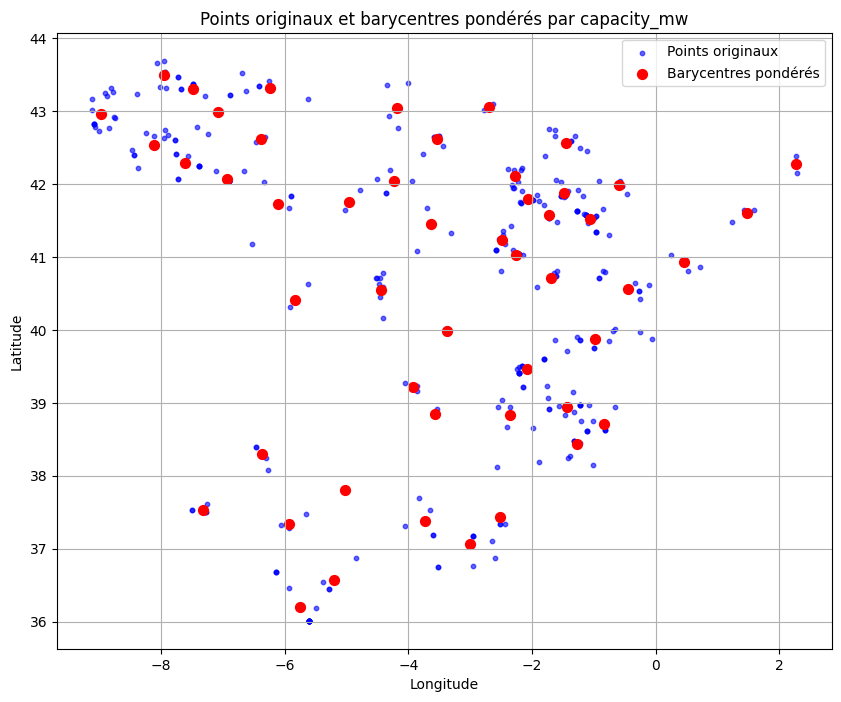

In [5]:
import matplotlib.pyplot as plt
# Plot
plt.figure(figsize=(10, 8))
# Points originaux
plt.scatter(df_wind_spain['longitude'], df_wind_spain['latitude'], c='blue', s=10, label='Points originaux', alpha=0.6)
# Barycentres pondérés
plt.scatter(df_grouped['longitude'], df_grouped['latitude'], c='red', s=50, label='Barycentres pondérés')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Points originaux et barycentres pondérés par capacity_mw')
plt.legend()
plt.grid(True)
plt.show()

C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11152\736836633.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_solar_spain['group'] = kmeans.fit_predict(coords)
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11152\736836633.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_grouped_solar = df_solar_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)


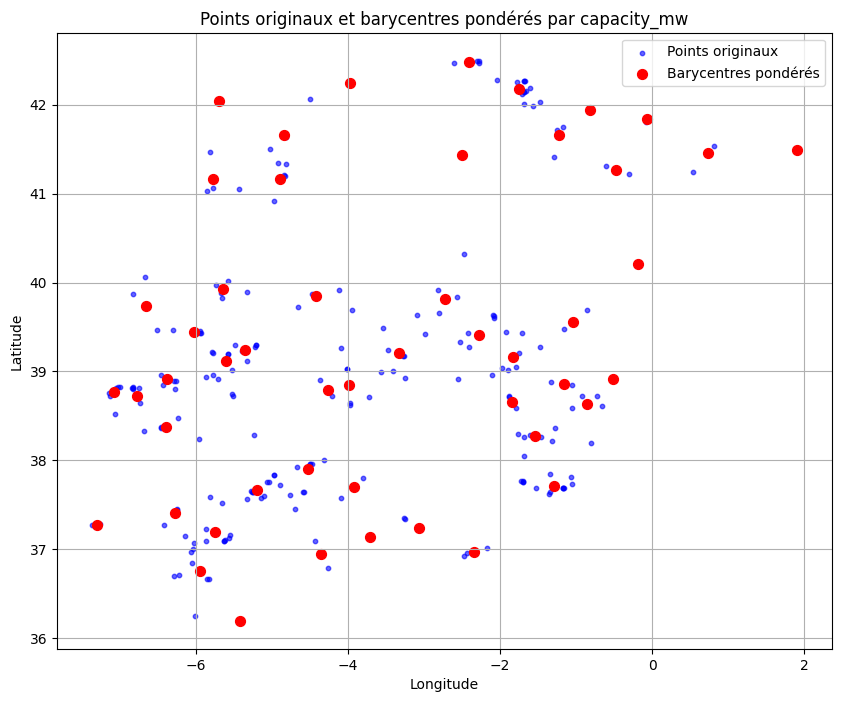

In [6]:
# Filter for Spain and renewable energy sources
df_solar_spain = df[(df['country'] == 'ESP') & (df['primary_fuel'].isin(['Solar'])) & (df['longitude'] < 10)& (df['longitude'] > -15)]
coords = df_solar_spain[['latitude', 'longitude']].values

# Appliquer KMeans avec 50 clusters
kmeans = KMeans(n_clusters=50, random_state=0)
df_solar_spain['group'] = kmeans.fit_predict(coords)
# Appliquer la fonction par groupe
df_grouped_solar = df_solar_spain.groupby('group').apply(weighted_centroid).reset_index(drop=True)

plt.figure(figsize=(10, 8))
# Points originaux
plt.scatter(df_solar_spain['longitude'], df_solar_spain['latitude'], c='blue', s=10, label='Points originaux', alpha=0.6)
# Barycentres pondérés
plt.scatter(df_grouped_solar['longitude'], df_grouped_solar['latitude'], c='red', s=50, label='Barycentres pondérés')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Points originaux et barycentres pondérés par capacity_mw')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Ajouter une colonne 'source' à chaque dataframe
df_grouped['source'] = 'wind'
df_grouped_solar['source'] = 'solar'

# Concaténer
df_wind_solar_spain = pd.concat([df_grouped, df_grouped_solar], ignore_index=True)

df_wind_solar_spain.to_csv('df_wind_solar_spain.csv', index=False) 

In [73]:
df_wind_solar_spain

,latitude,longitude,total_capacity_mw,source
0,41.524392,-1.066542,669.09,wind
1,41.174800,-6.519400,33.00,wind
2,37.253726,-3.680299,147.38,wind
3,43.301050,-6.315592,351.93,wind
4,36.046158,-5.612876,294.73,wind
...,...,...,...,...
95,38.636782,-0.860809,95.90,solar
96,38.843789,-3.987516,215.60,solar
97,41.162070,-4.894880,31.60,solar
98,38.658525,-1.839807,17.10,solar


In [8]:
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
import time
import os
os.chdir("C:\\Users\\DBT3KD\\Downloads")

# Configuration Open-Meteo
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Période d'intérêt
start_date = "2015-01-01"
end_date = "2023-12-31"


In [9]:

def download_wind_sun(df):
	all_data = []

	# Boucle sur les points
	for idx, row in df.iterrows():
		lat = row["latitude"]
		lon = row["longitude"]
		
		params = {
			"latitude": lat,
			"longitude": lon,
			"start_date": start_date,
			"end_date": end_date,
			"hourly": ["wind_speed_100m", "cloud_cover", "global_tilted_irradiance"]
		} 
		# ... à insérer dans ta boucle sur les points
		success = False
		while not success:
			try:
				responses = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)
				response = responses[0]

				hourly = response.Hourly()
				time_index = pd.date_range(
					start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
					end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
					freq=pd.Timedelta(seconds=hourly.Interval()),
					inclusive="left"
				)

				data = {
					"latitude": lat,
					"longitude": lon,
					"date": time_index,
					"wind_speed_100m": hourly.Variables(0).ValuesAsNumpy(),
					"cloud_cover": hourly.Variables(1).ValuesAsNumpy(),
					"global_tilted_irradiance": hourly.Variables(2).ValuesAsNumpy()
				}

				df_point = pd.DataFrame(data)
				all_data.append(df_point)

				print(f"✅ Fini pour point {idx+1}/{len(df)} ({lat}, {lon})")

				time.sleep(5)  # Facultatif : pour réduire la pression sur l'API

				success = True  # Sortie de boucle si réussite

			except Exception as e:
				# Gérer l'erreur de quota (limite API)
				if hasattr(e, 'args') and len(e.args) > 0 and 'request limit exceeded' in str(e.args[0]).lower():
					print(f"⏳ Limite de requêtes atteinte pour ({lat}, {lon}). Attente de 60 secondes...")
					time.sleep(60)
				else:
					print(f"⚠️ Échec pour le point {idx+1}/{len(df)} ({lat}, {lon}): {e}")
					success = True  # Ne pas boucler indéfiniment pour d'autres types d'erreurs
	return(all_data)


 

In [11]:
wind_dots = download_wind_sun(df_grouped)
wind_data = pd.concat(wind_dots, ignore_index=True)
wind_data.head(5)


✅ Fini pour point 1/50 (42.282150542551, -7.606360431310994)
✅ Fini pour point 2/50 (39.462994496634884, -2.0712209408300613)
✅ Fini pour point 3/50 (36.20597284984781, -5.74292528111086)
✅ Fini pour point 4/50 (41.52439161099404, -1.066541646116367)
✅ Fini pour point 5/50 (40.548457262081044, -4.447393000403824)
✅ Fini pour point 6/50 (37.06008317000426, -3.005067021729868)
✅ Fini pour point 7/50 (40.93095183275598, 0.45314235881736886)
✅ Fini pour point 8/50 (41.79453306367974, -2.0640536610661693)
✅ Fini pour point 9/50 (38.293446384720326, -6.371916916780355)
✅ Fini pour point 10/50 (43.49654587346919, -7.951702609032382)
✅ Fini pour point 11/50 (43.03812579800135, -4.175275861065296)
✅ Fini pour point 12/50 (42.62101654135338, -6.377151879699247)
✅ Fini pour point 13/50 (38.438323152527595, -1.269287450940928)
✅ Fini pour point 14/50 (42.03627488628202, -4.225523533636581)
✅ Fini pour point 15/50 (42.280789999999996, 2.2739450000000003)
✅ Fini pour point 16/50 (39.87096937682464, 

,latitude,longitude,date,wind_speed_100m,cloud_cover,global_tilted_irradiance
0,42.282151,-7.60636,2015-01-01 00:00:00+00:00,3.976330,16.0,0.0
1,42.282151,-7.60636,2015-01-01 01:00:00+00:00,3.671294,26.0,0.0
2,42.282151,-7.60636,2015-01-01 02:00:00+00:00,4.802999,33.0,0.0
3,42.282151,-7.60636,2015-01-01 03:00:00+00:00,8.089993,6.0,0.0
4,42.282151,-7.60636,2015-01-01 04:00:00+00:00,7.127636,0.0,0.0


In [12]:
os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
wind_data.to_parquet("wind_data.parquet", index=False)

In [15]:
sol_dots = download_wind_sun(df_grouped_solar)
sol_data = pd.concat(sol_dots, ignore_index=True)
sol_data.head(5)

✅ Fini pour point 1/50 (37.13364285714285, -3.713071428571429)
✅ Fini pour point 2/50 (42.18095626984126, -1.755912142857143)
✅ Fini pour point 3/50 (38.37440234741784, -6.399464084507043)
✅ Fini pour point 4/50 (37.714658546017006, -1.2953225831399844)
✅ Fini pour point 5/50 (41.66513617021277, -4.844761702127659)
✅ Fini pour point 6/50 (39.415246010638306, -2.2817925531914893)
✅ Fini pour point 7/50 (36.75899645390071, -5.952118034447822)
✅ Fini pour point 8/50 (38.786684210526325, -4.263368421052632)
✅ Fini pour point 9/50 (41.46046100960049, 0.741144471972747)
✅ Fini pour point 10/50 (38.91502840909091, -0.5099943181818181)
✅ Fini pour point 11/50 (37.665174151103564, -5.1926098684210515)
✅ Fini pour point 12/50 (39.2400021299639, -5.349957111913358)
✅ Fini pour point 13/50 (38.7695160295931, -7.0855285450061665)
✅ Fini pour point 14/50 (36.9716597826087, -2.3397739130434783)
✅ Fini pour point 15/50 (39.20484331983805, -3.3315272604588393)
✅ Fini pour point 16/50 (41.93923809523809

,latitude,longitude,date,wind_speed_100m,cloud_cover,global_tilted_irradiance
0,37.133643,-3.713071,2015-01-01 00:00:00+00:00,10.195057,0.0,0.0
1,37.133643,-3.713071,2015-01-01 01:00:00+00:00,10.440000,0.0,0.0
2,37.133643,-3.713071,2015-01-01 02:00:00+00:00,10.182337,0.0,0.0
3,37.133643,-3.713071,2015-01-01 03:00:00+00:00,9.931042,0.0,0.0
4,37.133643,-3.713071,2015-01-01 04:00:00+00:00,9.931042,0.0,0.0


In [16]:
print(sol_data.size)
print(wind_data.size)

23666400
23666400


In [17]:
os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")

sol_data.to_parquet("sol_data.parquet", index=False)